In [14]:
import torch
import torch.nn

from laya.pretrained_rlcd import pretrain_rlcd_step
from laya.pretrained import PretrainedDecisionModel

from laya.dataset import (
    encode_decision_batch,
    raw_examples,
    build_decision_examples,
    move_batch_to_device,
    LABELS,
)

from laya.sft import evaluate
from laya.decision_reward import downstream_reward


from transformers import AutoTokenizer
import matplotlib.pyplot as plt

import random

device = "cpu"

In [15]:
model_name = "bert-base-uncased"

In [16]:
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [17]:
examples = build_decision_examples(raw_examples, LABELS, seed=42)

In [18]:
# train valid split

rng = random.Random(123)

indices = list(range(len(examples)))
rng.shuffle(indices)

cut = 48
train_indices = indices[:cut]
validate_indices = indices[cut:]

train_examples = [examples[e] for e in train_indices]
validate_examples = [examples[e] for e in validate_indices]

In [19]:
train_batch = encode_decision_batch(train_examples, tokenizer)
validate_batch = encode_decision_batch(validate_examples, tokenizer)

train_targets = torch.tensor(
    [e["target"] for e in train_examples], dtype=torch.long
).to(device)
validate_targets = torch.tensor(
    [e["target"] for e in validate_examples], dtype=torch.long
).to(device)

train_batch = move_batch_to_device(train_batch, device)
validate_batch = move_batch_to_device(validate_batch, device)

### decision head only


In [20]:
rlcd_model = PretrainedDecisionModel(model_name, decision_hidden_dim=128)
rlcd_model.load_state_dict(
    torch.load("../model/sft_model.pt", map_location="cpu", weights_only=True)
)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 24375.52it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<All keys matched successfully>

In [21]:
for para in rlcd_model.backbone.parameters():
    para.requires_grad = False

optimizer = torch.optim.AdamW(rlcd_model.decision_head.parameters(), lr=1e-5)

baseline


In [22]:
before_loss, before_accuracy, before_proba = evaluate(
    rlcd_model,
    input_ids=validate_batch["input_ids"],
    attention_mask=validate_batch["attention_mask"],
    option_marker_mask=validate_batch["option_marker_mask"],
    targets=validate_targets,
)
before_utility = downstream_reward(before_proba, validate_targets).mean().item()
before_loss, before_accuracy, before_utility, before_proba

(1.7698965072631836,
 0.5833333134651184,
 -0.3750000298023224,
 tensor([[4.7702e-04, 4.4586e-04, 4.5188e-04, 9.9863e-01, 0.0000e+00, 0.0000e+00],
         [5.2739e-02, 5.5385e-02, 8.9188e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [3.3024e-03, 3.2386e-03, 9.9346e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [5.1352e-03, 2.2834e-03, 2.2812e-03, 9.9030e-01, 0.0000e+00, 0.0000e+00],
         [3.5174e-01, 3.1412e-01, 3.3414e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [3.5854e-01, 1.5075e-01, 1.6356e-01, 1.7515e-01, 1.5200e-01, 0.0000e+00],
         [6.1146e-01, 4.2347e-05, 4.2272e-05, 4.3465e-05, 3.8841e-01, 0.0000e+00],
         [8.3473e-05, 9.9962e-01, 7.3866e-05, 7.3334e-05, 7.2293e-05, 7.9326e-05],
         [8.9849e-05, 9.9977e-01, 6.8903e-05, 6.9279e-05, 0.0000e+00, 0.0000e+00],
         [3.4996e-01, 5.0925e-01, 9.1266e-02, 4.9525e-02, 0.0000e+00, 0.0000e+00],
         [2.4849e-01, 2.6293e-01, 2.4993e-01, 2.3864e-01, 0.0000e+00, 0.0000e+00],
         [9.9975e-01, 8

train


In [23]:
rlcd_loss_history = []
rlcd_reward_history = []

n_steps = 200

for step in range(n_steps):
    loss, reward = pretrain_rlcd_step(
        rlcd_model,
        optimizer,
        train_batch["input_ids"],
        train_batch["attention_mask"],
        train_batch["option_marker_mask"],
        train_targets,
        n_candidates=32,
        exploration_std=0.2,
        scoring_weight=0.5,
    )
    rlcd_loss_history.append(loss)
    rlcd_reward_history.append(reward)

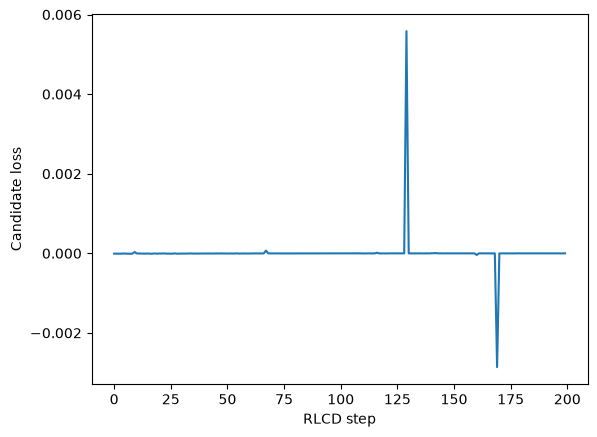

In [24]:
plt.figure()

plt.plot(
    rlcd_loss_history,
)

plt.xlabel("RLCD step")
plt.ylabel("Candidate loss")

plt.show()

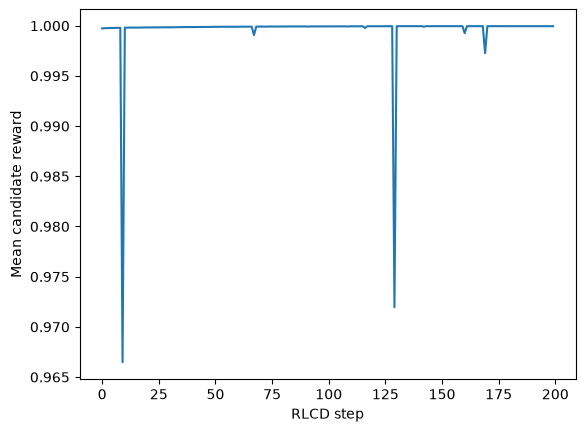

In [25]:
plt.figure()

plt.plot(
    rlcd_reward_history,
)

plt.xlabel("RLCD step")
plt.ylabel("Mean candidate reward")

plt.show()

In [26]:
after_loss, after_accuracy, after_proba = evaluate(
    rlcd_model,
    input_ids=validate_batch["input_ids"],
    attention_mask=validate_batch["attention_mask"],
    option_marker_mask=validate_batch["option_marker_mask"],
    targets=validate_targets,
)
after_utility = downstream_reward(after_proba, validate_targets).mean().item()
after_loss, after_accuracy, after_utility, after_proba

(1.9531089067459106,
 0.5833333134651184,
 -0.3750000298023224,
 tensor([[1.3441e-04, 1.2692e-04, 1.2874e-04, 9.9961e-01, 0.0000e+00, 0.0000e+00],
         [4.0370e-02, 4.1448e-02, 9.1818e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [1.5093e-03, 1.4734e-03, 9.9702e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [2.1312e-03, 9.4387e-04, 9.4527e-04, 9.9598e-01, 0.0000e+00, 0.0000e+00],
         [3.5572e-01, 3.1137e-01, 3.3291e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [3.6244e-01, 1.5086e-01, 1.6228e-01, 1.7157e-01, 1.5285e-01, 0.0000e+00],
         [6.3855e-01, 8.1291e-06, 8.1661e-06, 8.3103e-06, 3.6142e-01, 0.0000e+00],
         [1.4911e-05, 9.9993e-01, 1.3097e-05, 1.3023e-05, 1.2781e-05, 1.3761e-05],
         [1.6590e-05, 9.9996e-01, 1.2770e-05, 1.2840e-05, 0.0000e+00, 0.0000e+00],
         [3.4977e-01, 5.3154e-01, 7.7229e-02, 4.1456e-02, 0.0000e+00, 0.0000e+00],
         [2.4987e-01, 2.5879e-01, 2.5151e-01, 2.3983e-01, 0.0000e+00, 0.0000e+00],
         [9.9995e-01, 1

### full model


In [27]:
rlcd_model = PretrainedDecisionModel(model_name, decision_hidden_dim=128)
rlcd_model.load_state_dict(
    torch.load("../model/sft_model.pt", map_location="cpu", weights_only=True)
)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 23136.34it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<All keys matched successfully>

In [28]:
for para in rlcd_model.backbone.parameters():
    para.requires_grad = True

optimizer = torch.optim.AdamW(
    [
        {
            "params": rlcd_model.backbone.parameters(),
            "lr": 1e-6,
        },
        {
            "params": rlcd_model.decision_head.parameters(),
            "lr": 1e-5,
        },
    ]
)

train


In [29]:
rlcd_loss_history = []
rlcd_reward_history = []

n_steps = 200

for step in range(n_steps):
    loss, reward = pretrain_rlcd_step(
        rlcd_model,
        optimizer,
        train_batch["input_ids"],
        train_batch["attention_mask"],
        train_batch["option_marker_mask"],
        train_targets,
        n_candidates=32,
        exploration_std=0.2,
        scoring_weight=0.5,
    )
    rlcd_loss_history.append(loss)
    rlcd_reward_history.append(reward)

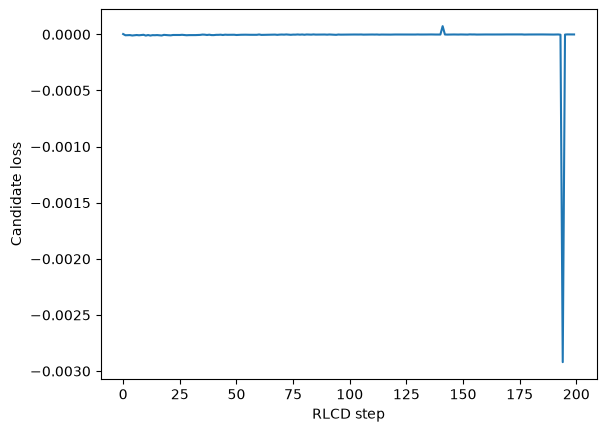

In [30]:
plt.figure()

plt.plot(
    rlcd_loss_history,
)

plt.xlabel("RLCD step")
plt.ylabel("Candidate loss")

plt.show()

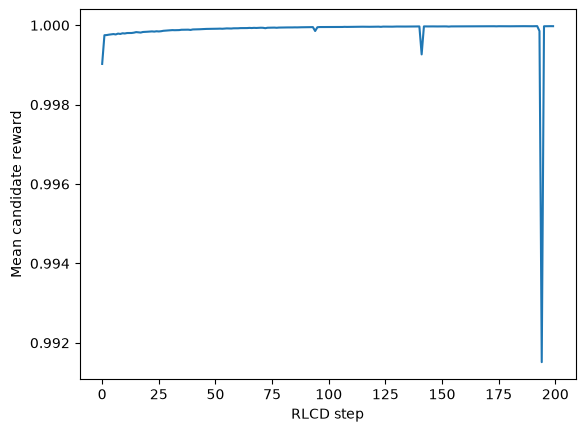

In [31]:
plt.figure()

plt.plot(
    rlcd_reward_history,
)

plt.xlabel("RLCD step")
plt.ylabel("Mean candidate reward")

plt.show()

In [32]:
after_loss, after_accuracy, after_proba = evaluate(
    rlcd_model,
    input_ids=validate_batch["input_ids"],
    attention_mask=validate_batch["attention_mask"],
    option_marker_mask=validate_batch["option_marker_mask"],
    targets=validate_targets,
)
after_utility = downstream_reward(after_proba, validate_targets).mean().item()
after_loss, after_accuracy, after_utility, after_proba

(1.088757038116455,
 0.5,
 -0.17500001192092896,
 tensor([[2.7681e-02, 2.6477e-02, 2.6851e-02, 9.1899e-01, 0.0000e+00, 0.0000e+00],
         [2.8303e-01, 2.7161e-01, 4.4536e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [2.4236e-01, 2.3675e-01, 5.2088e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [2.5203e-01, 2.0419e-01, 2.0449e-01, 3.3929e-01, 0.0000e+00, 0.0000e+00],
         [3.5518e-01, 3.1336e-01, 3.3146e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [3.1124e-01, 1.7057e-01, 1.7323e-01, 1.7222e-01, 1.7273e-01, 0.0000e+00],
         [9.9997e-01, 5.8927e-06, 5.9094e-06, 5.9002e-06, 1.4499e-05, 0.0000e+00],
         [6.4324e-06, 9.9997e-01, 5.8728e-06, 5.8071e-06, 5.7223e-06, 5.8043e-06],
         [1.0393e-05, 9.9997e-01, 9.0881e-06, 9.1137e-06, 0.0000e+00, 0.0000e+00],
         [4.7949e-01, 2.0370e-01, 1.5787e-01, 1.5894e-01, 0.0000e+00, 0.0000e+00],
         [2.5665e-01, 2.4935e-01, 2.4929e-01, 2.4471e-01, 0.0000e+00, 0.0000e+00],
         [9.9998e-01, 7.9391e-06, 7.53